<a href="https://colab.research.google.com/github/Mamoun-AL-Sayaraa/Study-Room-Application/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Modify the linear regression script to work for logistic regression**

Epoch 0, Loss: 0.6885, Gradient: [ 0.         -0.48499512 -0.48015348]
Epoch 300, Loss: 0.1985, Gradient: [-0.00427724 -0.15949252 -0.15584151]
Epoch 600, Loss: 0.1144, Gradient: [-0.00618396 -0.09016281 -0.08756708]
Epoch 900, Loss: 0.0814, Gradient: [-0.00646757 -0.0626714  -0.06068266]
Epoch 1200, Loss: 0.0638, Gradient: [-0.00631097 -0.04809533 -0.04649192]
Epoch 1500, Loss: 0.0528, Gradient: [-0.00603233 -0.03908534 -0.03774731]
Epoch 1800, Loss: 0.0452, Gradient: [-0.00572955 -0.03296575 -0.03182136]
Epoch 2100, Loss: 0.0397, Gradient: [-0.00543548 -0.02853644 -0.02753943]
Epoch 2400, Loss: 0.0355, Gradient: [-0.00516086 -0.02518039 -0.0242992 ]
Epoch 2700, Loss: 0.0321, Gradient: [-0.00490829 -0.02254833 -0.02176044]

 Intercept (w0): 0.15870255711968043
Coefficients: [2.11404541 2.06073017]
Accuracy: 100.00%

Actual | Predicted
     0 |         0
     0 |         0
     0 |         0
     0 |         0
     0 |         0
     0 |         0
     0 |         0
     0 |         0


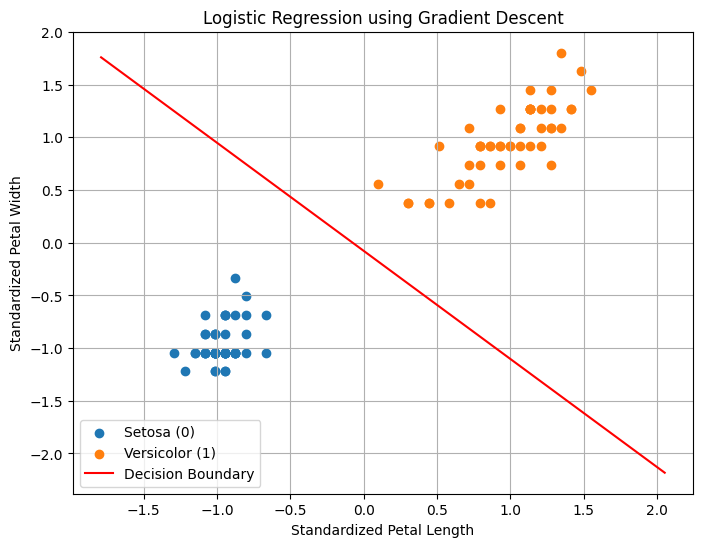

In [10]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def gradient_descent(X, y, learning_rate=0.01, epochs=3000):
    m = len(y)
    X_b = np.c_[np.ones(m), X]
    W = np.zeros(X_b.shape[1])

    for epoch in range(epochs):
        probabilities = sigmoid(X_b @ W)
        gradient = X_b.T @ (probabilities - y) / m
        W -= learning_rate * gradient

        if epoch % 300 == 0:
            p = np.clip(sigmoid(X_b @ W), 1e-10, 1 - 1e-10)
            loss = -np.mean(y * np.log(p) + (1-y) * np.log(1-p))
            print(f"Epoch {epoch}, Loss: {loss:.4f}, Gradient: {gradient}")

    return W


# Load Iris dataset and select two classes
iris = load_iris()
mask = iris.target < 2
X = iris.data[mask][:, [2, 3]]
y = iris.target[mask]

# Standardize features
X = (X - X.mean(axis=0)) / X.std(axis=0)

# Train model
W = gradient_descent(X, y)
print("\n Intercept (w0):", W[0])
print("Coefficients:", W[1:])

# Predict classes
X_b = np.c_[np.ones(len(X)), X]
probabilities = sigmoid(X_b @ W)
predictions = (probabilities >= 0.5).astype(int)
print(f"Accuracy: {np.mean(predictions == y) * 100:.2f}%")
print("\nActual | Predicted")

for i in range(len(y)):
    print(f"{y[i]:6d} | {predictions[i]:9d}")

# Plot classification results
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], label="Setosa (0)")
plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Versicolor (1)")

# Decision boundary: W0 + W1*x1 + W2*x2 = 0
x1 = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200)
if abs(W[2]) > 1e-10:
    x2 = -(W[0] + W[1] * x1) / W[2]
    plt.plot(x1, x2, "r-", label="Decision Boundary")

plt.xlabel("Standardized Petal Length")
plt.ylabel("Standardized Petal Width")
plt.title("Logistic Regression using Gradient Descent")
plt.legend()
plt.grid(True)
plt.show()
